# IPL 2022 Capstone Project

The **Indian Premier League (IPL)** is a professional T20 cricket league in India, featuring franchises representing different cities. This project explores **IPL 2022 match-level data** to derive meaningful insights and understand **match outcomes, player performances, and team dynamics**.

## Dataset Columns

The following are some of the important columns that we will focus on to derive meaningful insights:

| Column Name | Variable Type |
|---|---|
| `date` | String |
| `venue` | String |
| `stage` | String |
| `team1` | String |
| `team2` | String |
| `toss_winner` | String |
| `toss_decision` | String |
| `first_ings_score` | Integer |
| `second_ings_score` | Integer |
| `match_winner` | String |
| `won_by` | String |
| `margin` | Integer |
| `player_of_the_match` | String |
| `top_scorer` | String |
| `highscore` | Integer |
| `best_bowling` | String |
| `best_bowling_figure` | String |

In [ ]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings 
warnings.filterwarnings("ignore")


df = pd.read_csv("IPL.csv")
df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,133,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,179,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,208,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,161,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,149,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22


# Basic Information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   match_id             74 non-null     int64 
 1   date                 74 non-null     object
 2   venue                74 non-null     object
 3   team1                74 non-null     object
 4   team2                74 non-null     object
 5   stage                74 non-null     object
 6   toss_winner          74 non-null     object
 7   toss_decision        74 non-null     object
 8   first_ings_score     74 non-null     int64 
 9   first_ings_wkts      74 non-null     int64 
 10  second_ings_score    74 non-null     int64 
 11  second_ings_wkts     74 non-null     int64 
 12  match_winner         74 non-null     object
 13  won_by               74 non-null     object
 14  margin               74 non-null     int64 
 15  player_of_the_match  74 non-null     object
 16  top_scorer

Check the size of rows and columns of the dataset

In [ ]:
print(f"your rows are {df.shape[0]} and your columns are {df.shape[1]}")

your rows are 74 and your columns are 20


Now let's see how many columns have null values in total.

In [ ]:
df.isnull().sum()

match_id               0
date                   0
venue                  0
team1                  0
team2                  0
stage                  0
toss_winner            0
toss_decision          0
first_ings_score       0
first_ings_wkts        0
second_ings_score      0
second_ings_wkts       0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64

# Now, Here comes some Basic Questions

1. Which team won the most matches?

Text(0, 0.5, 'Team')

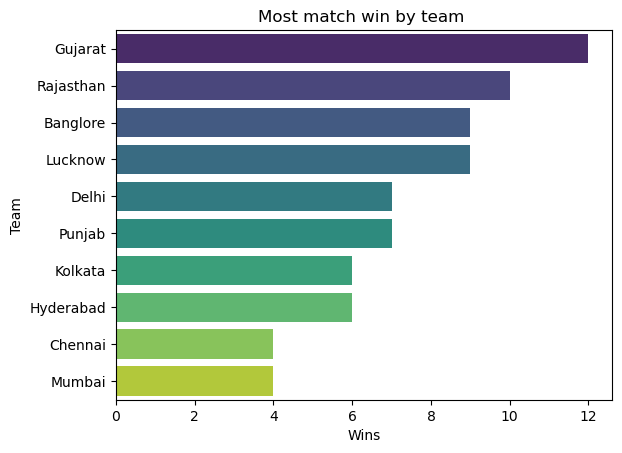

In [ ]:
match_wins = df['match_winner'].value_counts()
sns.barplot(y = match_wins.index,x = match_wins.values,palette='viridis')
plt.title("Most match win by team ")
plt.xlabel("Wins")
plt.ylabel("Team")

2. Toss Decision Trends

Text(0.5, 1.0, 'Toss Decision Trends ')

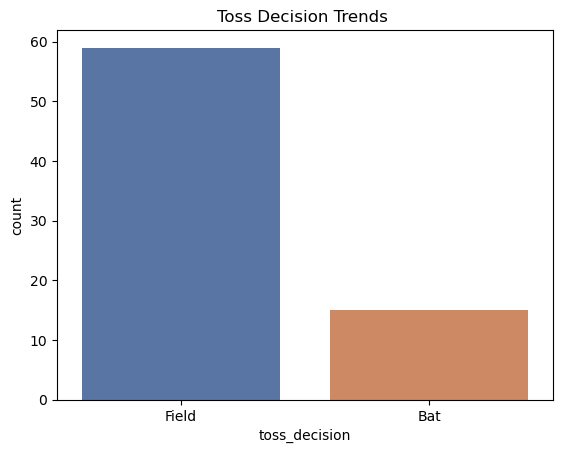

In [ ]:
sns.countplot(x = df['toss_decision'], palette= "deep")
plt.title("Toss Decision Trends ")

3. Toss Winner vs Match Winner

In [ ]:
count = df[df['toss_winner'] == df['match_winner']]['match_id'].count()
percentage = (count *100)/df.shape[0]
print(f"{percentage.round(2)} %")

48.65 %


4. How do teams win? (Runs vs Wickets)

Text(0.5, 1.0, 'Won by')

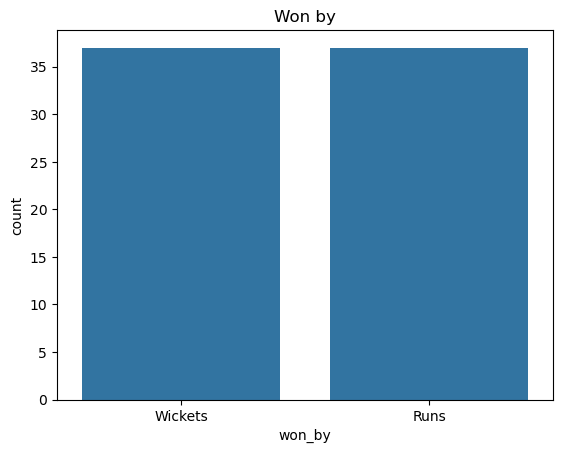

In [ ]:
sns.countplot(x = df["won_by"])
plt.title("Won by")

# Key Player Performances

1. Most "Player of the Match" Awards

In [ ]:
count = df['player_of_the_match'].value_counts().head(10)
count


player_of_the_match
Kuldeep Yadav      4
Jos Buttler        3
Umesh Yadav        2
Quinton de Kock    2
David Miller       2
Umran Malik        2
K L Rahul          2
Rahul Tripathi     2
Hardik Pandya      2
Jasprit Bumrah     2
Name: count, dtype: int64

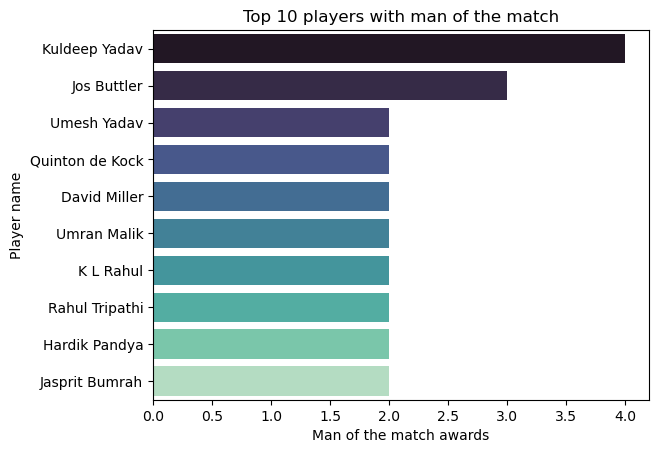

In [ ]:
sns.barplot(x = count.values , y = count.index, palette='mako')
plt.title("Top 10 players with man of the match")
plt.xlabel("Man of the match awards")
plt.ylabel("Player name")
plt.show()

2. Top Scorers

In [ ]:
high = df.groupby('top_scorer')['highscore'].sum().sort_values(ascending=False).head(5)
high

top_scorer
Jos Buttler        651
Quinton de Kock    377
KL Rahul           351
Shubman Gill       288
Faf du Plessis     257
Name: highscore, dtype: int64

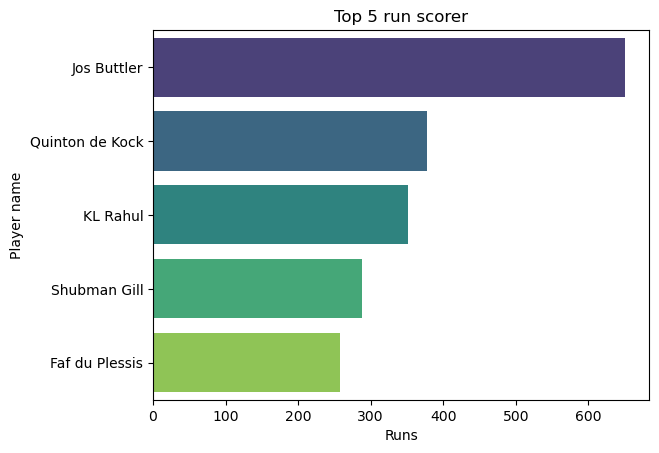

In [ ]:
sns.barplot(x = high.values , y = high.index, palette='viridis')
plt.title("Top 5 run scorer")
plt.xlabel("Runs")
plt.ylabel("Player name")
plt.show()

3. 10 Best Bowling Figures

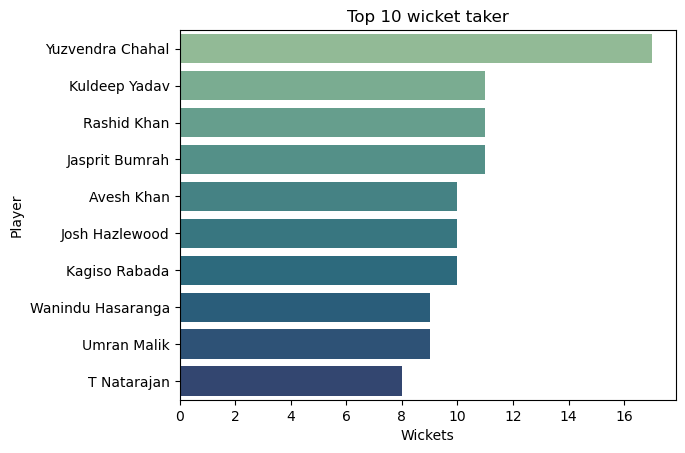

In [ ]:
df['highest_wickets'] = df['best_bowling_figure'].apply(lambda x :x.split('--')[0])
df['highest_wickets'] = df['highest_wickets'].astype(int)

top_bowlers = df.groupby('best_bowling')['highest_wickets'].sum().sort_values(ascending=False).head(10)
sns.barplot(x = top_bowlers.values , y = top_bowlers.index, palette='crest')

plt.title("Top 10 wicket taker")
plt.xlabel("Wickets")
plt.ylabel("Player")
plt.show()

# Venue Analysis

Most Matches Played by Venue

In [ ]:
venue_count = df['venue'].value_counts()
venue_count

venue
Wankhede Stadium, Mumbai                        21
Dr DY Patil Sports Academy, Mumbai              20
Brabourne Stadium, Mumbai                       16
Maharashtra Cricket Association Stadium,Pune    13
Eden Gardens, Kolkata                            2
Narendra Modi Stadium, Ahmedabad                 2
Name: count, dtype: int64

<Axes: ylabel='venue'>

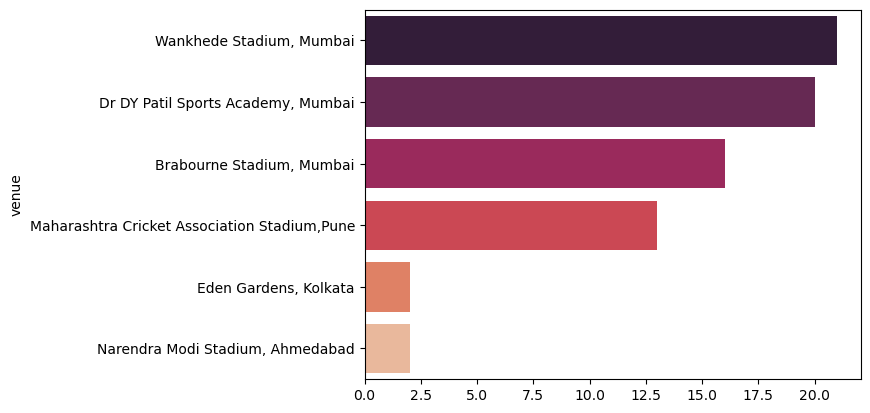

In [ ]:
sns.barplot(y = venue_count.index,x = venue_count.values,palette='rocket')

# Match Scoring Analysis

Which matches had the highest combined score from both innings?

In [ ]:
df['total_score'] = (df['first_ings_score'] + df['second_ings_score'])

top_matches = df.sort_values(by='total_score',ascending=False).head(10)

top_matches[['team1', 'team2', 'first_ings_score', 'second_ings_score', 'total_score']]

,team1,team2,first_ings_score,second_ings_score,total_score
33,Delhi,Rajasthan,222,207,429
29,Kolkata,Rajasthan,217,210,427
6,Chennai,Lucknow,210,211,421
65,Kolkata,Lucknow,210,208,418
2,Banglore,Punjab,205,208,413
21,Banglore,Chennai,216,193,409
71,Banglore,Lucknow,207,193,400
39,Gujarat,Hyderabad,195,199,394
49,Delhi,Hyderabad,207,186,393
45,Chennai,Hyderabad,202,189,391


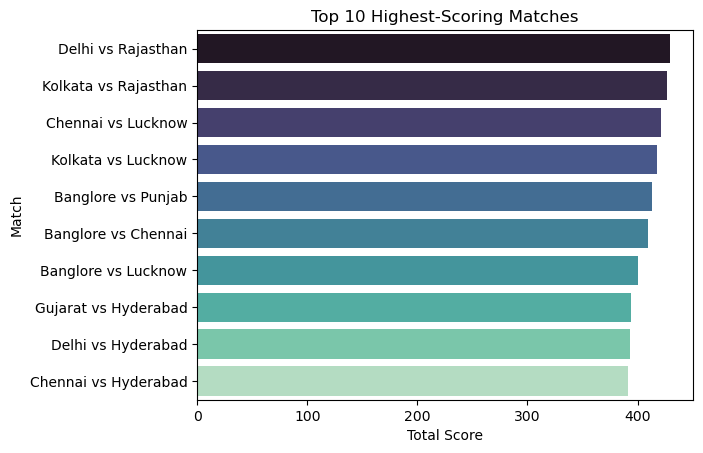

In [ ]:
match_name = ( top_matches['team1'] +' vs ' +top_matches['team2'])

sns.barplot(x = top_matches['total_score'], y = match_name, palette="mako")

plt.xlabel('Total Score')
plt.ylabel('Match')
plt.title('Top 10 Highest-Scoring Matches')
plt.show()

# Most Wickets Lost in a Match

Which matches had the highest combined number of wickets lost by both teams?

In [ ]:
df['total_wickets_lost'] = (df['first_ings_wkts'] +df['second_ings_wkts'])

top_wicket_matches = df.sort_values( by='total_wickets_lost', ascending = False).head(10)

top_wicket_matches[['team1', 'team2', 'first_ings_wkts', 'second_ings_wkts', 'total_wickets_lost']]

,team1,team2,first_ings_wkts,second_ings_wkts,total_wickets_lost
55,Kolkata,Mumbai,9,10,19
38,Banglore,Rajasthan,8,10,18
59,Banglore,Punjab,9,9,18
10,Chennai,Punjab,8,10,18
34,Gujarat,Kolkata,9,8,17
52,Kolkata,Lucknow,7,10,17
5,Banglore,Kolkata,10,7,17
48,Banglore,Chennai,8,8,16
8,Mumbai,Rajasthan,8,8,16
54,Chennai,Delhi,6,10,16


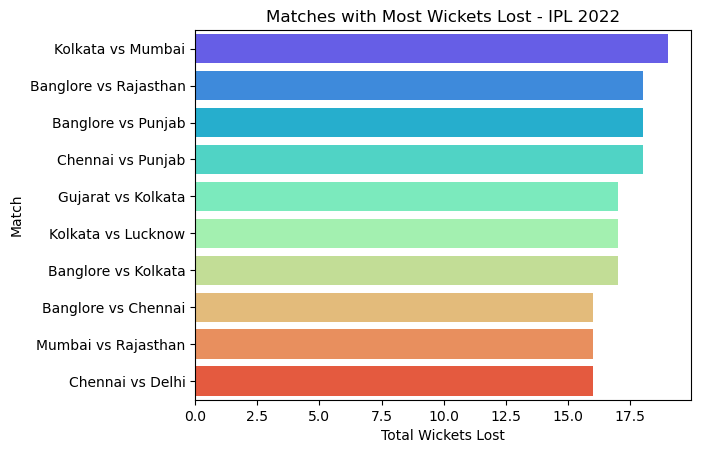

In [ ]:
match_name = (top_wicket_matches['team1'] +' vs ' + top_wicket_matches['team2'])

sns.barplot(x = top_wicket_matches['total_wickets_lost'], y = match_name, palette="rainbow")

plt.xlabel('Total Wickets Lost')
plt.ylabel('Match')
plt.title('Matches with Most Wickets Lost - IPL 2022')
plt.show()

# Toss Decision by Tournament Stage

Did teams prefer different toss decisions at different stages of IPL 2022?

In [ ]:
toss_stage = pd.crosstab(
    df['stage'],
    df['toss_decision']
)

toss_stage

toss_decision,Bat,Field
stage,,
Final,1,0
Group,14,56
Playoff,0,3


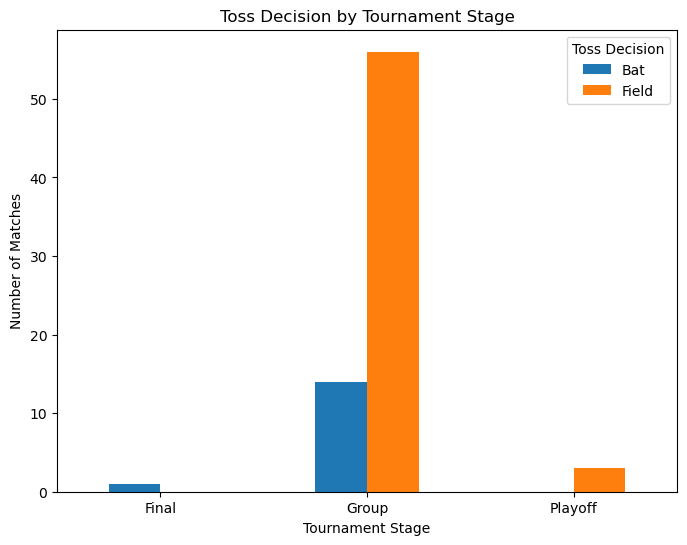

In [ ]:
toss_stage.plot(kind='bar', figsize=(8,6))

plt.xlabel('Tournament Stage')
plt.ylabel('Number of Matches')
plt.title('Toss Decision by Tournament Stage')
plt.xticks(rotation=0)
plt.legend(title='Toss Decision')

plt.show()

# Custom Questions & Insights

1. Who won the highest margin by runs?

In [ ]:
df[df['won_by'] == 'Runs'].sort_values(by = 'margin',ascending=False).head(1)[['match_winner','margin',]]

,match_winner,margin
54,Chennai,91


2. Which player had the highest individual score?

In [ ]:
df[df['highscore'] == df['highscore'].max()][['top_scorer','highscore']]

,top_scorer,highscore
65,Quinton de Kock,140


3. Which bowler had the best bowling figures?

In [ ]:
df[df['highest_wickets'] == df['highest_wickets'].max()][['best_bowling','best_bowling_figure']]

,best_bowling,best_bowling_figure
29,Yuzvendra Chahal,5--40
39,Umran Malik,5--25
53,Wanindu Hasaranga,5--18
55,Jasprit Bumrah,5--10
